## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. The dataset: `Superstore Dataset (vivek468).zip` is already in `C:\Users\sivan\Datasets` (made from [Kaggle – US Superstore (vivek468)](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)).
3. When the upload cell asks for a file, choose `Superstore Dataset (vivek468).zip` from `C:\Users\sivan\Datasets`.

**Run the cells from top to bottom** (Shift+Enter runs one cell). After a restart, run them again from the top.

# Daily Challenge: Strategic Analysis of Superstore Performance

## 👩‍🏫 👩🏿‍🏫 What You’ll learn
- Translate business objectives into data analysis questions.
- Use Matplotlib and Seaborn for diagnostic and communicative visualizations.
- Create interactive widgets for dynamic exploration.
- Derive and present actionable insights from retail sales data.
- Structure a professional analysis notebook and executive summary.

## Setup
> **New here: `ipywidgets`.** Gives sliders and dropdowns inside the notebook. `interact(function, x=widget)` re-runs the function whenever the widget changes. When the notebook is saved/executed without a live kernel only the default choice is shown, so after each widget we also draw one fixed chart.

In [1]:
import pandas as pd
# tables
import numpy as np
# math
import matplotlib.pyplot as plt
# charts
import seaborn as sns
# statistical charts
import ipywidgets as widgets
# sliders, dropdowns
from ipywidgets import interact, Dropdown, IntSlider
# the widget tools we use
from IPython.display import display
# to show objects in the notebook
import warnings
# to control warning messages
warnings.filterwarnings('ignore')
# hide warnings to keep the output clean
sns.set_theme(style='whitegrid')
# seaborn style

---
## 1. Data Scoping and Preparation
Dataset: US Superstore orders (9,994 orders, 2014–2017). Run the upload cell, then load the data and do a preliminary assessment.
The file is not UTF-8, so we read it with `encoding='latin1'`.

In [ ]:
from google.colab import files
# the Colab tool for uploading files from your computer
uploaded = files.upload()
# choose "Superstore Dataset (vivek468).zip" (saved in a variable so its contents are not printed)
!unzip "Superstore Dataset (vivek468).zip"
# unzip it: you get the file "superstore_dataset.csv"

In [2]:
df = pd.read_csv('superstore_dataset.csv', encoding='latin1')
# read the file (latin1 = the text encoding this file uses)
print(df.shape)
# rows, columns
df.head()
# first rows

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.info()
# column types and non-empty counts

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [4]:
df.describe()
# statistics of the number columns

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [5]:
df.isna().sum()
# missing values per column

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

---
## 1a. 🧹 Handle missing values and duplicates
*Justification:* the check above shows **no missing values**, so no `dropna()`/`fillna()` is needed (filling would only invent data). We also check for duplicate rows; there are none, and every `Row ID` is unique, so nothing is removed.

In [6]:
print('Missing values:', df.isna().sum().sum())
# total missing values in the whole table
print('Duplicate rows:', df.duplicated().sum())
# rows that are exact copies
df = df.drop_duplicates()
# safe step: removes duplicates if any exist (here none)

Missing values: 0
Duplicate rows: 0


---
## 1b. 🕓 Fix data types

In [7]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
# text like '11/8/2016' -> real date (month/day/year)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
# same for the ship date
df[['Order Date', 'Ship Date']].dtypes
# check: both are datetime now

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

---
## 1c. 🏗️ Feature engineering

In [8]:
df['Profit Margin'] = df['Profit'] / df['Sales'] * 100
# profit as % of sales
df['Order Year'] = df['Order Date'].dt.year
# year of the order
df['Order Month'] = df['Order Date'].dt.month
# month number (1-12)
df['Order Month-Year'] = df['Order Date'].dt.to_period('M').dt.to_timestamp()
# first day of the order's month, e.g. 2016-11-01 (to group by month)
df[['Order Date', 'Sales', 'Profit', 'Profit Margin', 'Order Year', 'Order Month', 'Order Month-Year']].head()
# check the new columns

,Order Date,Sales,Profit,Profit Margin,Order Year,Order Month,Order Month-Year
0,2016-11-08,261.9600,41.9136,16.00,2016,11,2016-11-01
1,2016-11-08,731.9400,219.5820,30.00,2016,11,2016-11-01
2,2016-06-12,14.6200,6.8714,47.00,2016,6,2016-06-01
3,2015-10-11,957.5775,-383.0310,-40.00,2015,10,2015-10-01
4,2015-10-11,22.3680,2.5164,11.25,2015,10,2015-10-01


---
## 2a. 📈 Time-Series Trend Analysis (Matplotlib)

In [9]:
def plot_monthly_sales(category):
    # draws total monthly sales, for all products or one category
    if category == 'All':
        data = df
        # use every order
    else:
        data = df[df['Category'] == category]
        # only orders from this category
    monthly = data.groupby('Order Month-Year')['Sales'].sum()
    # total sales per month
    plt.figure(figsize=(12, 4))
    # wide chart
    plt.plot(monthly.index, monthly.values, marker='o', color='teal')
    # the monthly line
    plt.title(f'Total Monthly Sales – {category}')
    # title
    plt.xlabel('Month')
    # x label
    plt.ylabel('Sales ($)')
    # y label
    plt.grid(True)
    # grid lines
    plt.show()
    # show the chart

category_dropdown = Dropdown(options=['All'] + sorted(df['Category'].unique()), value='All', description='Category:')
# dropdown with All + the 3 categories
interact(plot_monthly_sales, category=category_dropdown);
# choose a category and the chart updates

interactive(children=(Dropdown(description='Category:', options=('All', 'Furniture', 'Office Supplies', 'Techn…

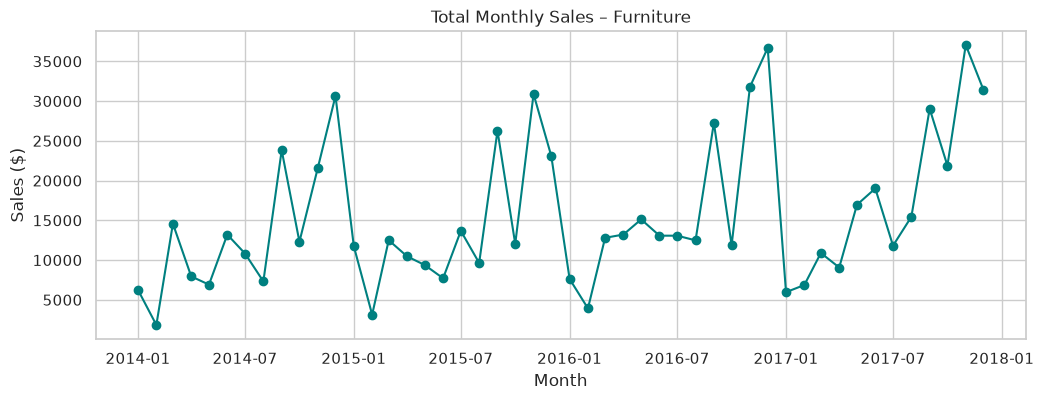

In [10]:
plot_monthly_sales('Furniture')
# a fixed example for one category

*Observations:*
- **Seasonality:** every year sales are lowest in January–February and peak in **September, November and December** (back-to-school and holiday season).
- **Year-over-year:** total sales grow from about \$484k (2014) to \$733k (2017); 2015 was flat, 2016–2017 grew strongly.
- **Products:** all 3 categories show the same end-of-year peaks; Technology has the biggest single-month spikes.

---
## 2b. 🗺️ Geographic Sales Performance

In [11]:
state_sales = df.groupby('State')['Sales'].sum().sort_values(ascending=False)
# total sales per state, biggest first

def plot_top_states(top_n):
    # horizontal bars for the top_n states
    top_states = state_sales.head(top_n)
    # the best top_n states
    plt.figure(figsize=(10, max(4, top_n * 0.35)))
    # taller chart for more states
    plt.barh(top_states.index[::-1], top_states.values[::-1], color='slateblue')
    # [::-1] reverses, so the biggest bar is on top
    plt.title(f'Top {top_n} States by Total Sales')
    # title
    plt.xlabel('Sales ($)')
    # x label
    plt.xlim(0, top_states.max() * 1.1)
    # room on the right (template bug fixed: .max() instead of max(... .values()))
    plt.show()
    # show the chart

interact(plot_top_states, top_n=IntSlider(min=3, max=len(state_sales), value=10, description='Top N:'));
# slider to choose how many states

interactive(children=(IntSlider(value=10, description='Top N:', max=49, min=3), Output()), _dom_classes=('widg…

In [12]:
share = state_sales.head(5).sum() / state_sales.sum() * 100
# % of all sales made in the top 5 states
print(f'{len(state_sales)} states, the top 5 make {share:.0f}% of all sales')
# show it

49 states, the top 5 make 52% of all sales


*Observations:* **California** (~\$458k) and **New York** (~\$311k) lead, then Texas, Washington and Pennsylvania. Sales are **quite centralized**: the top 5 of 49 states make about 52% of all sales, and many states sell very little.

---
## 3a. 🏆 Top 10 Most Profitable Products (Seaborn)

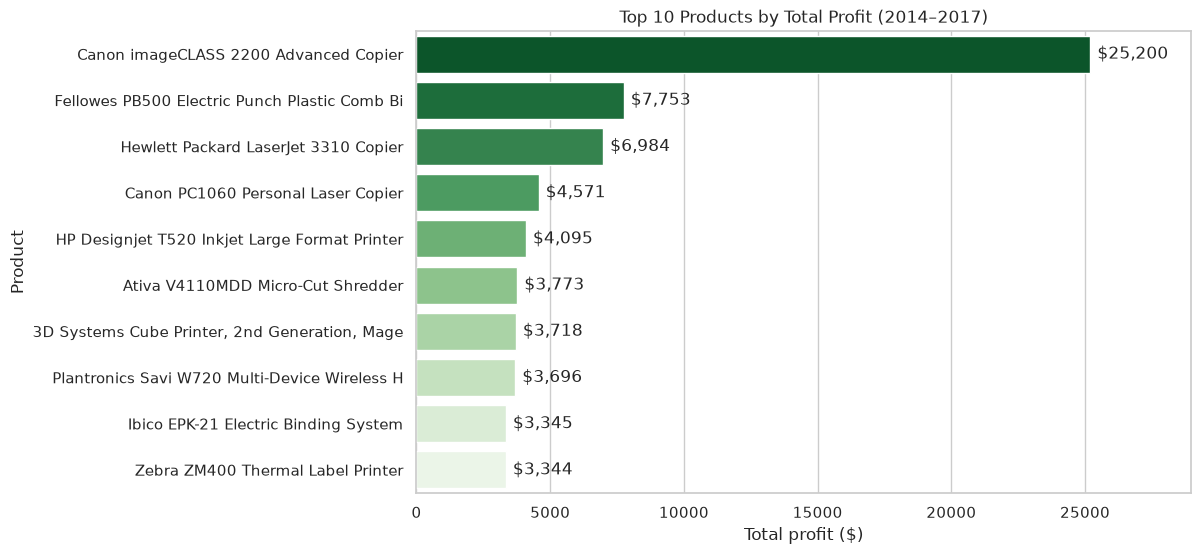

In [13]:
top_products = df.groupby('Product Name')['Profit'].sum().nlargest(10).reset_index()
# the 10 products with the highest total profit
top_products['Short Name'] = top_products['Product Name'].str.slice(0, 45)
# shorten long names so the chart is readable
plt.figure(figsize=(10, 6))
# chart size
ax = sns.barplot(data=top_products, x='Profit', y='Short Name', palette='Greens_r')
# horizontal bars (y = product)
for i, profit in enumerate(top_products['Profit']):
    # go through each bar
    ax.annotate(f'${profit:,.0f}', xy=(profit, i), xytext=(5, 0), textcoords='offset points', va='center')
    # write the exact profit at the end of the bar
plt.title('Top 10 Products by Total Profit (2014–2017)')
# executive-ready title
plt.xlabel('Total profit ($)')
# x label
plt.ylabel('Product')
# y label
plt.xlim(0, top_products['Profit'].max() * 1.15)
# room for the numbers
plt.show()
# show the chart

The **Canon imageCLASS 2200 copier** alone made ~\$25k profit, over 3× the next product. Most top products are office machines (copiers, binding machines, printers) – Technology/Office Supplies.

---
## 3b. 🔍 Discount vs Profit

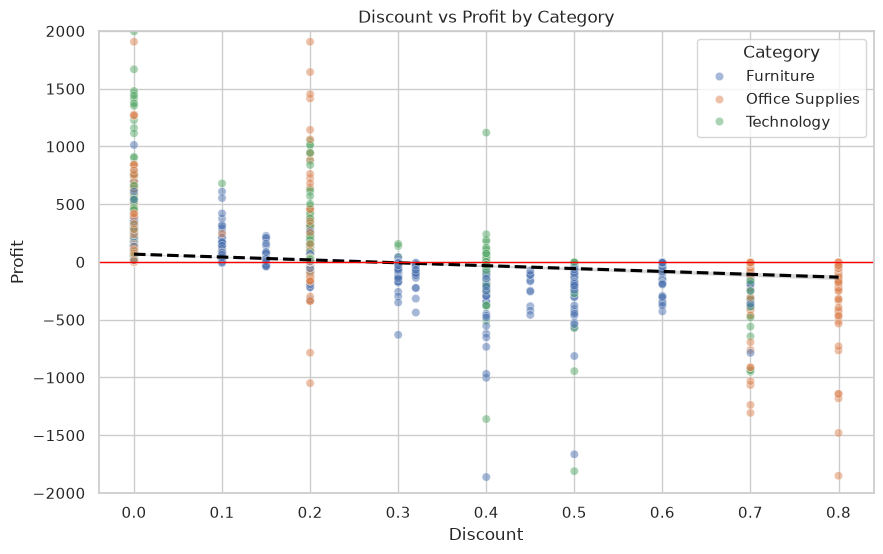

In [14]:
plt.figure(figsize=(10, 6))
# chart size
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.5)
# one dot per order, colored by category
sns.regplot(data=df, x='Discount', y='Profit', scatter=False, color='black', line_kws={'linestyle': '--'})
# trend line for all orders (scatter=False: only the line)
plt.axhline(0, color='red', linewidth=1)
# red line at profit = 0
plt.ylim(-2000, 2000)
# zoom in (a few extreme orders hide the pattern)
plt.title('Discount vs Profit by Category')
# title
plt.show()
# show the chart

In [15]:
by_discount = df.groupby('Discount')['Profit'].agg(['mean', 'count'])
# average profit and number of orders per discount level
by_discount['% loss orders'] = df.groupby('Discount')['Profit'].apply(lambda p: (p < 0).mean() * 100)
# % of orders that lose money at each discount
by_discount.round(1)
# show the table

,mean,count,% loss orders
Discount,,,
0.00,66.9,4798,0.0
0.10,96.1,94,4.3
0.15,27.3,52,32.7
0.20,24.7,3657,13.7
0.30,-45.7,227,91.6
0.32,-88.6,27,100.0
0.40,-111.9,206,87.4
0.45,-226.6,11,100.0
0.50,-310.7,66,100.0


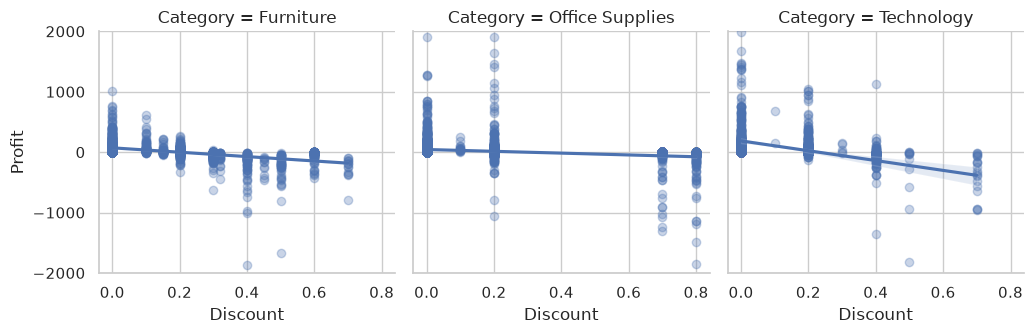

In [16]:
sns.lmplot(data=df, x='Discount', y='Profit', col='Category', scatter_kws={'alpha': 0.3}, height=3.5)
# one regression chart per category, to compare trends
plt.ylim(-2000, 2000)
# same zoom
plt.show()
# show

*Observations:* up to **20% discount** orders are profitable on average. From **30% and up** losses become consistent (about 90–100% of these orders lose money). All three categories go down as discount rises; the drop is steepest for **Technology** and **Furniture** (big-ticket items lose the most per order).

---
## 4. Methodology and Tooling Review

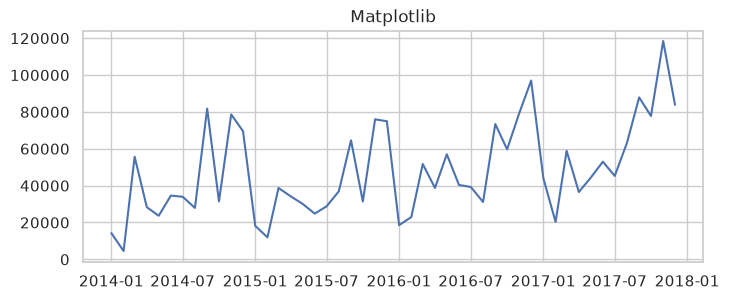

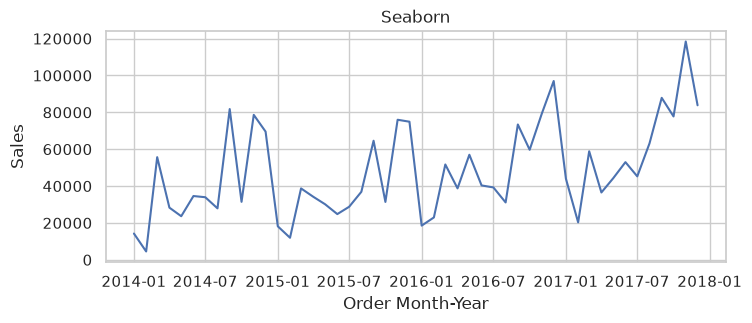

Matplotlib: 0.08s   Seaborn: 0.10s


In [17]:
import time
# to measure time
monthly = df.groupby('Order Month-Year')['Sales'].sum().reset_index()
# data for both charts
start = time.time()
# start timer
plt.figure(figsize=(8, 3)); plt.plot(monthly['Order Month-Year'], monthly['Sales']); plt.title('Matplotlib'); plt.show()
# the line chart with Matplotlib
mpl_time = time.time() - start
# how long it took
start = time.time()
# restart timer
plt.figure(figsize=(8, 3)); sns.lineplot(data=monthly, x='Order Month-Year', y='Sales'); plt.title('Seaborn'); plt.show()
# the same chart with Seaborn
sns_time = time.time() - start
# how long it took
print(f'Matplotlib: {mpl_time:.2f}s   Seaborn: {sns_time:.2f}s')
# compare

Both are fast for this data. **Matplotlib** gave full control (annotations, axis limits, reversed bars, widgets redraw). **Seaborn** made grouped/statistical charts in one line (`hue`, `regplot`, `lmplot`, nice palettes).

*Recommendation:* “For rapid exploration, I will use **Seaborn** because one line gives grouped, colored and statistical charts straight from the DataFrame. For stakeholder-facing presentations, I will prefer **Matplotlib (often on top of Seaborn)** because I can control every label, annotation and layout detail.”

---
## 5. Executive Summary

In [18]:
print('Total sales: $', round(df['Sales'].sum()), '| Total profit: $', round(df['Profit'].sum()))
# overall numbers
df.groupby('Category')[['Sales', 'Profit']].sum().assign(Margin=lambda t: t['Profit'] / t['Sales'] * 100).round(1)
# sales, profit and margin per category

Total sales: $ 2297201 | Total profit: $ 286397


,Sales,Profit,Margin
Category,,,
Furniture,741999.8,18451.3,2.5
Office Supplies,719047.0,122490.8,17.0
Technology,836154.0,145454.9,17.4


- **Growth & seasonality:** sales grew ~51% from 2014 (\$484k) to 2017 (\$733k); Sept, Nov and Dec are the peak months → plan stock and marketing for Q4.
- **Discounts kill profit:** orders at ≥30% discount almost always lose money. **Cap standard discounts at 20%.**
- **Furniture is the weak category:** similar sales to the others (~\$742k) but only ~\$18k profit (2.5% margin); Tables and Bookcases lose money → review pricing/discounts for them.
- **Technology is the profit engine** (~\$145k profit, 17% margin), led by copiers (Canon imageCLASS 2200 ≈ \$25k profit) → promote these.
- **Sales are concentrated:** California and New York lead; the top 5 states make ~52% of sales → protect these markets and test growth in weaker states.

---
## 🧠 Optional Advanced Challenges
### Dashboard (ipywidgets)

In [19]:
def dashboard(region):
    # 2 charts for one region (or all)
    data = df if region == 'All' else df[df['Region'] == region]
    # filter the region
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    # two charts side by side
    data.groupby('Order Month-Year')['Sales'].sum().plot(ax=axes[0], color='teal')
    # left: monthly sales
    axes[0].set_title(f'Monthly Sales – {region}')
    # title
    data.groupby('Category')['Profit'].sum().plot(kind='bar', ax=axes[1], color=['brown', 'orange', 'green'])
    # right: profit per category
    axes[1].set_title(f'Profit by Category – {region}')
    # title
    plt.tight_layout()
    # no overlap
    plt.show()
    # show

interact(dashboard, region=Dropdown(options=['All'] + sorted(df['Region'].unique()), description='Region:'));
# choose a region and both charts update

interactive(children=(Dropdown(description='Region:', options=('All', 'Central', 'East', 'South', 'West'), val…

### Annotate outliers in Discount vs Profit

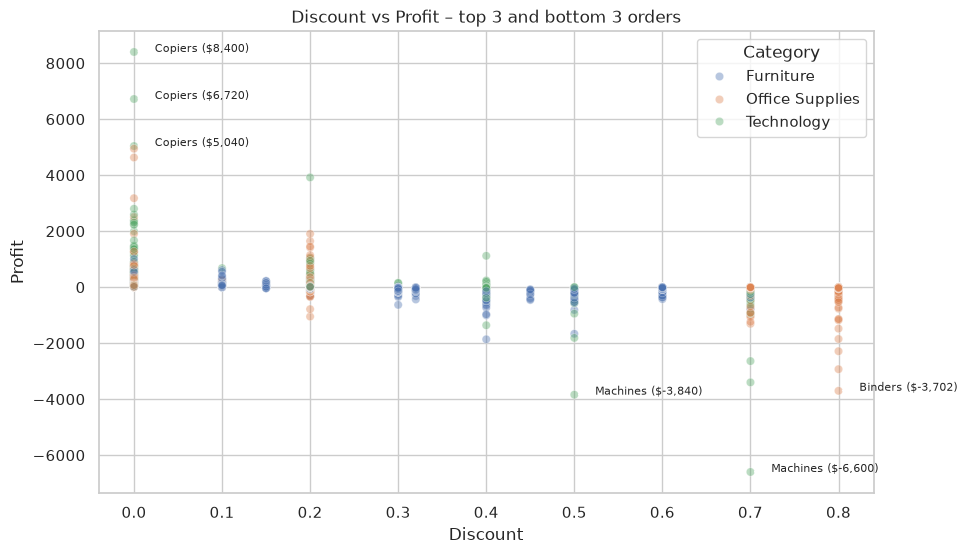

In [20]:
best = df.nlargest(3, 'Profit')
# 3 most profitable orders
worst = df.nsmallest(3, 'Profit')
# 3 biggest losses
plt.figure(figsize=(10, 6))
# chart size
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.4)
# all orders
for _, row in pd.concat([best, worst]).iterrows():
    # go through the 6 outliers
    plt.annotate(row['Sub-Category'] + f" (${row['Profit']:,.0f})", xy=(row['Discount'], row['Profit']),
                 xytext=(15, 0), textcoords='offset points', arrowprops=dict(arrowstyle='->'), fontsize=8)
    # arrow + label (template typo 'arowstyle' fixed to 'arrowstyle')
plt.title('Discount vs Profit – top 3 and bottom 3 orders')
# title
plt.show()
# show

### Plotly Express version
> **New here: Plotly Express.** Makes interactive charts (hover, zoom) with one line. `trendline='ols'` adds a regression line (needs the `statsmodels` package). Compared with Matplotlib + ipywidgets, Plotly is interactive without writing a function, but is harder to fine-tune for print.

In [21]:
import plotly.express as px
# interactive charts
fig = px.scatter(df, x='Discount', y='Profit', color='Category', trendline='ols', hover_data=['Product Name'],
                 title='Discount vs Profit (Plotly – hover over a dot)')
# scatter with a trend line per category and product name on hover
fig.show()
# show the interactive chart